In [ ]:
#1 Import pandas to work with tables and datasets
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib to create graphs
import matplotlib.pyplot as plt

# Import tools to split data into training and testing sets
from sklearn.model_selection import train_test_split

# Import tools to evaluate our classification model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import tools to convert text into numerical values
from sklearn.feature_extraction.text import TfidfVectorizer

# Import Logistic Regression machine learning algorithm
from sklearn.linear_model import LogisticRegression

# Import a tool to save our trained model
import joblib

# Display a success message
print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
#2 Load the customer support CSV file
df = pd.read_csv("synthetic_customer_support_tickets_1000.csv")

# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display the column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display the first five tickets
print("\nFirst Five Tickets:")
print(df.head())

# Count the different ticket categories
print("\nCategory Counts:")
print(df["category"].value_counts())

# Count the different priority levels
print("\nPriority Counts:")
print(df["priority"].value_counts())

Dataset Shape: (1000, 6)

Column Names:
['ticket_id', 'subject', 'description', 'category', 'priority', 'language']

First Five Tickets:
   ticket_id                subject  \
0  TKT-00522           Damaged item   
1  TKT-00738           Missing item   
2  TKT-00741         Order tracking   
3  TKT-00661           Missing item   
4  TKT-00412  Website loading error   

                                         description   category priority  \
0  I am contacting support because tracking says ...      Order   Medium   
1  I am contacting support because the product ar...      Order     High   
2  I am contacting support because my order was c...      Order   Medium   
3  I am contacting support because my package has...      Order   Medium   
4  I am contacting support because the applicatio...  Technical      Low   

  language  
0  English  
1  English  
2  English  
3  English  
4  English  

Category Counts:
category
Order        250
Technical    250
Account      250
Billing      25

In [ ]:
#3 Check for missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check how many unique ticket descriptions exist
print("\nUnique Ticket Descriptions:")
print(df["description"].nunique())

# Check the number of tickets in each category
print("\nCategory Distribution:")
print(df["category"].value_counts())

# Check the number of tickets in each priority level
print("\nPriority Distribution:")
print(df["priority"].value_counts())

Missing Values:
ticket_id      0
subject        0
description    0
category       0
priority       0
language       0
dtype: int64

Duplicate Rows:
0

Unique Ticket Descriptions:
128

Category Distribution:
category
Order        250
Technical    250
Account      250
Billing      250
Name: count, dtype: int64

Priority Distribution:
priority
Medium    469
High      343
Low       188
Name: count, dtype: int64


In [8]:
#4 Combine the ticket subject and description into one text column
df["ticket_text"] = df["subject"] + ". " + df["description"]

# Store ticket text as the input for our machine learning model
X = df["ticket_text"]

# Store category as the first prediction target
y_category = df["category"]

# Store priority as the second prediction target
y_priority = df["priority"]

# Display the prepared input and targets
print("Input data shape:", X.shape)

print("\nCategory target shape:", y_category.shape)

print("\nPriority target shape:", y_priority.shape)

# Display one example ticket
print("\nExample ticket:")
print(X.iloc[0])

print("\nActual category:", y_category.iloc[0])
print("Actual priority:", y_priority.iloc[0])

Input data shape: (1000,)

Category target shape: (1000,)

Priority target shape: (1000,)

Example ticket:
Damaged item. I am contacting support because tracking says delivered but I cannot find the package. I can share the order number and a photo if required. Please help me resolve this issue.

Actual category: Order
Actual priority: Medium


In [9]:
#5 Import the tool used to split datasets
from sklearn.model_selection import train_test_split

# First, separate 70% training data and 30% temporary data
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["category"]
)

# Divide the temporary data equally into validation and testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["category"]
)

# Prepare training inputs and targets
X_train = train_df["ticket_text"]
y_train_category = train_df["category"]
y_train_priority = train_df["priority"]

# Prepare validation inputs and targets
X_val = val_df["ticket_text"]
y_val_category = val_df["category"]
y_val_priority = val_df["priority"]

# Prepare testing inputs and targets
X_test = test_df["ticket_text"]
y_test_category = test_df["category"]
y_test_priority = test_df["priority"]

# Display the number of tickets in each group
print("Training tickets:", len(X_train))
print("Validation tickets:", len(X_val))
print("Testing tickets:", len(X_test))

print("\nData splitting completed!")

Training tickets: 700
Validation tickets: 150
Testing tickets: 150

Data splitting completed!


In [10]:
#6 Import the TF-IDF text conversion tool
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF converter
tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words="english"
)

# Learn vocabulary from training tickets and convert them into numbers
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert validation tickets using the same learned vocabulary
X_val_tfidf = tfidf.transform(X_val)

# Convert testing tickets using the same learned vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display the shapes of the converted data
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nText conversion completed!")

Training TF-IDF shape: (700, 162)
Validation TF-IDF shape: (150, 162)
Testing TF-IDF shape: (150, 162)

Text conversion completed!


In [11]:
#7 Import the Logistic Regression algorithm
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
category_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using training ticket data
category_model.fit(X_train_tfidf, y_train_category)

# Predict categories for validation tickets
category_predictions = category_model.predict(X_val_tfidf)

# Display the first 10 actual and predicted categories
print("Actual Categories:")
print(y_val_category.head(10).tolist())

print("\nPredicted Categories:")
print(category_predictions[:10])

print("\nCategory model training completed!")

Actual Categories:
['Account', 'Billing', 'Account', 'Billing', 'Billing', 'Account', 'Order', 'Account', 'Order', 'Billing']

Predicted Categories:
['Account' 'Billing' 'Account' 'Billing' 'Billing' 'Account' 'Order'
 'Account' 'Order' 'Billing']

Category model training completed!


In [ ]:
#8 Import the accuracy calculation tool
from sklearn.metrics import accuracy_score, classification_report

# Calculate validation accuracy
category_accuracy = accuracy_score(
    y_val_category,
    category_predictions
)

# Display the accuracy as a percentage
print("Category Validation Accuracy:",
      round(category_accuracy * 100, 2), "%")

# Display precision, recall and F1-score for each category
print("\nClassification Report:")
print(classification_report(
    y_val_category,
    category_predictions,
    zero_division=0
))

Category Validation Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

     Account       1.00      1.00      1.00        37
     Billing       1.00      1.00      1.00        38
       Order       1.00      1.00      1.00        37
   Technical       1.00      1.00      1.00        38

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150



Confusion Matrix:
[[37  0  0  0]
 [ 0 38  0  0]
 [ 0  0 37  0]
 [ 0  0  0 38]]


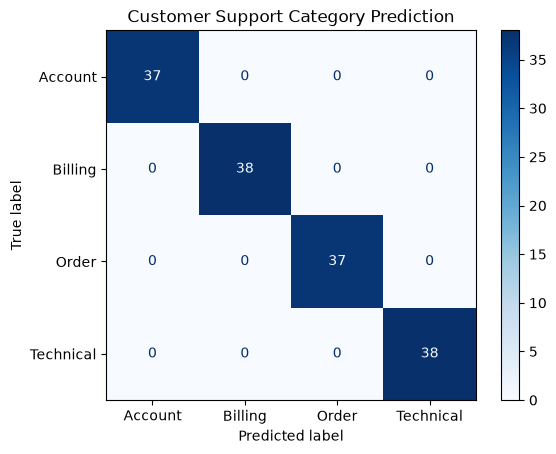

In [ ]:
#9 Import confusion matrix and plotting tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(
    y_val_category,
    category_predictions,
    labels=category_model.classes_
)

# Display the confusion matrix
print("Confusion Matrix:")
print(cm)

# Create a visual confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=category_model.classes_
)

display.plot(cmap="Blues", values_format="d")
plt.title("Customer Support Category Prediction")
plt.show()

In [14]:
#10 Create a Logistic Regression model for priority prediction
priority_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using training ticket data
priority_model.fit(X_train_tfidf, y_train_priority)

# Predict priority for validation tickets
priority_predictions = priority_model.predict(X_val_tfidf)

# Display the first 10 actual priorities
print("Actual Priorities:")
print(y_val_priority.head(10).tolist())

# Display the first 10 predicted priorities
print("\nPredicted Priorities:")
print(priority_predictions[:10])

print("\nPriority model training completed!")

Actual Priorities:
['High', 'Medium', 'High', 'High', 'Medium', 'High', 'High', 'Low', 'Medium', 'Medium']

Predicted Priorities:
['High' 'Medium' 'High' 'High' 'Medium' 'High' 'High' 'Medium' 'Medium'
 'Medium']

Priority model training completed!


In [15]:
#11 Import evaluation tools
from sklearn.metrics import accuracy_score, classification_report

# Calculate priority prediction accuracy
priority_accuracy = accuracy_score(
    y_val_priority,
    priority_predictions
)

# Display accuracy as a percentage
print("Priority Validation Accuracy:",
      round(priority_accuracy * 100, 2), "%")

# Display precision, recall and F1-score
print("\nPriority Classification Report:")
print(classification_report(
    y_val_priority,
    priority_predictions,
    zero_division=0
))

Priority Validation Accuracy: 80.0 %

Priority Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        54
         Low       0.58      0.41      0.48        34
      Medium       0.72      0.84      0.78        62

    accuracy                           0.80       150
   macro avg       0.77      0.75      0.75       150
weighted avg       0.79      0.80      0.79       150



Priority Confusion Matrix:
[[54  0  0]
 [ 0 14 20]
 [ 0 10 52]]


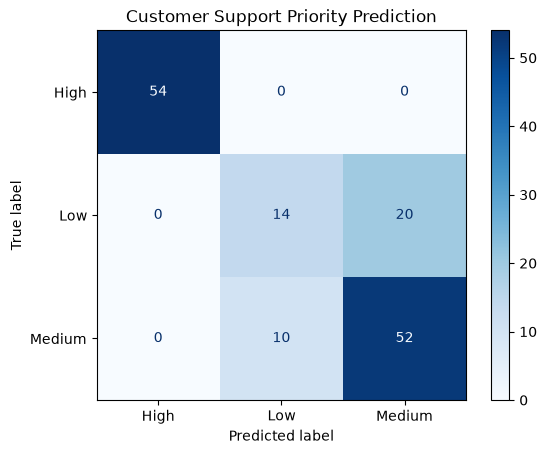

In [ ]:
#12 Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the priority confusion matrix
priority_cm = confusion_matrix(
    y_val_priority,
    priority_predictions,
    labels=priority_model.classes_
)

# Display the confusion matrix values
print("Priority Confusion Matrix:")
print(priority_cm)

# Create a visual confusion matrix
priority_display = ConfusionMatrixDisplay(
    confusion_matrix=priority_cm,
    display_labels=priority_model.classes_
)

priority_display.plot(cmap="Blues", values_format="d")
plt.title("Customer Support Priority Prediction")
plt.show()

In [17]:
#13 Create a table containing both model results
results_df = pd.DataFrame({
    "Model": [
        "Category Prediction",
        "Priority Prediction"
    ],
    "Validation Accuracy": [
        category_accuracy,
        priority_accuracy
    ]
})

# Convert accuracy into percentage
results_df["Validation Accuracy"] = (
    results_df["Validation Accuracy"] * 100
)

# Display the comparison table
print(results_df)

                 Model  Validation Accuracy
0  Category Prediction                100.0
1  Priority Prediction                 80.0


In [18]:
#14 Create a new customer support ticket
new_ticket = [
    "Payment issue. My card was charged twice for the same order. Please help me."
]

# Convert the new ticket using our existing TF-IDF converter
new_ticket_tfidf = tfidf.transform(new_ticket)

# Predict the ticket category
predicted_category = category_model.predict(new_ticket_tfidf)

# Predict the ticket priority
predicted_priority = priority_model.predict(new_ticket_tfidf)

# Display the predictions
print("New Customer Ticket:")
print(new_ticket[0])

print("\nPredicted Category:", predicted_category[0])
print("Predicted Priority:", predicted_priority[0])

New Customer Ticket:
Payment issue. My card was charged twice for the same order. Please help me.

Predicted Category: Billing
Predicted Priority: High


In [19]:
#15 Save the TF-IDF text converter
joblib.dump(tfidf, "ticket_tfidf.pkl")

# Save the category prediction model
joblib.dump(category_model, "ticket_category_model.pkl")

# Save the priority prediction model
joblib.dump(priority_model, "ticket_priority_model.pkl")

# Display a success message
print("All models saved successfully!")

All models saved successfully!


In [20]:
#16 Load the saved TF-IDF converter
loaded_tfidf = joblib.load("ticket_tfidf.pkl")

# Load the saved category model
loaded_category_model = joblib.load("ticket_category_model.pkl")

# Load the saved priority model
loaded_priority_model = joblib.load("ticket_priority_model.pkl")

# Display a success message
print("All saved models loaded successfully!")

All saved models loaded successfully!


In [21]:
#17 Create a new customer support ticket
test_ticket = [
    "My account is locked and I cannot sign in. Please help me."
]

# Convert the ticket using the loaded TF-IDF converter
test_ticket_tfidf = loaded_tfidf.transform(test_ticket)

# Predict category using the loaded model
category_result = loaded_category_model.predict(test_ticket_tfidf)

# Predict priority using the loaded model
priority_result = loaded_priority_model.predict(test_ticket_tfidf)

# Display the results
print("Customer Ticket:")
print(test_ticket[0])

print("\nPredicted Category:", category_result[0])
print("Predicted Priority:", priority_result[0])

Customer Ticket:
My account is locked and I cannot sign in. Please help me.

Predicted Category: Account
Predicted Priority: High


In [22]:
#18 Convert test tickets using the trained TF-IDF converter
X_test_tfidf = loaded_tfidf.transform(X_test)

# Predict categories for test tickets
test_category_predictions = loaded_category_model.predict(X_test_tfidf)

# Predict priorities for test tickets
test_priority_predictions = loaded_priority_model.predict(X_test_tfidf)

# Calculate final category accuracy
test_category_accuracy = accuracy_score(
    y_test_category,
    test_category_predictions
)

# Calculate final priority accuracy
test_priority_accuracy = accuracy_score(
    y_test_priority,
    test_priority_predictions
)

# Display final test results
print("FINAL TEST RESULTS")

print("\nCategory Accuracy:",
      round(test_category_accuracy * 100, 2), "%")

print("Priority Accuracy:",
      round(test_priority_accuracy * 100, 2), "%")

FINAL TEST RESULTS

Category Accuracy: 100.0 %
Priority Accuracy: 81.33 %


In [23]:
#19 Display the final category classification report
print("CATEGORY MODEL TEST REPORT")
print(classification_report(
    y_test_category,
    test_category_predictions,
    zero_division=0
))

# Display the final priority classification report
print("\nPRIORITY MODEL TEST REPORT")
print(classification_report(
    y_test_priority,
    test_priority_predictions,
    zero_division=0
))

CATEGORY MODEL TEST REPORT
              precision    recall  f1-score   support

     Account       1.00      1.00      1.00        38
     Billing       1.00      1.00      1.00        37
       Order       1.00      1.00      1.00        38
   Technical       1.00      1.00      1.00        37

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150


PRIORITY MODEL TEST REPORT
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        56
         Low       0.57      0.27      0.36        30
      Medium       0.72      0.91      0.81        64

    accuracy                           0.81       150
   macro avg       0.77      0.72      0.72       150
weighted avg       0.80      0.81      0.79       150



In [24]:
#20 Create a final model comparison table
final_results = pd.DataFrame({
    "Model": ["Category Prediction", "Priority Prediction"],
    "Test Accuracy": [
        test_category_accuracy * 100,
        test_priority_accuracy * 100
    ]
})

# Save the results to a CSV file
final_results.to_csv("model_comparison_results.csv", index=False)

print("Final evaluation results saved successfully!")
print(final_results)

Final evaluation results saved successfully!
                 Model  Test Accuracy
0  Category Prediction     100.000000
1  Priority Prediction      81.333333


In [26]:
#21 Part 2 — DistilBERT
import torch
import transformers
import accelerate

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Accelerate version:", accelerate.__version__)

print("\nGPU available:", torch.cuda.is_available())
print("Installation check completed!")

d:\ai-training-week3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.15.0+cpu
Transformers version: 5.22.2
Accelerate version: 1.15.0

GPU available: False
Installation check completed!


In [27]:
import os

print("CPU cores available:", os.cpu_count())
print("PyTorch device: CPU")
print("Ready for DistilBERT setup!")

CPU cores available: 4
PyTorch device: CPU
Ready for DistilBERT setup!


In [32]:
# 22
from transformers import AutoTokenizer

# Select the DistilBERT pretrained model
model_name = "distilbert-base-uncased"

# Load its tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

print("DistilBERT tokenizer loaded successfully!")

DistilBERT tokenizer loaded successfully!


In [33]:
#23 Convert training tickets into DistilBERT tokens
train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

# Convert validation tickets into tokens
val_encodings = tokenizer(
    X_val.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

# Convert test tickets into tokens
test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

print("Training tickets tokenized:", len(train_encodings["input_ids"]))
print("Validation tickets tokenized:", len(val_encodings["input_ids"]))
print("Testing tickets tokenized:", len(test_encodings["input_ids"]))
print("\nTokenization completed!")

Training tickets tokenized: 700
Validation tickets tokenized: 150
Testing tickets tokenized: 150

Tokenization completed!


In [34]:
# 24
from sklearn.preprocessing import LabelEncoder

# Convert category names into numeric labels
category_encoder = LabelEncoder()

y_train_cat = category_encoder.fit_transform(y_train_category)
y_val_cat = category_encoder.transform(y_val_category)
y_test_cat = category_encoder.transform(y_test_category)

# Display category-to-number mapping
print("Category mapping:")

for number, category in enumerate(category_encoder.classes_):
    print(number, "=", category)

print("\nCategory labels prepared successfully!")

Category mapping:
0 = Account
1 = Billing
2 = Order
3 = Technical

Category labels prepared successfully!


In [35]:
# 25
from sklearn.preprocessing import LabelEncoder

# Convert priority names into numeric labels
priority_encoder = LabelEncoder()

y_train_pri = priority_encoder.fit_transform(y_train_priority)
y_val_pri = priority_encoder.transform(y_val_priority)
y_test_pri = priority_encoder.transform(y_test_priority)

# Display priority-to-number mapping
print("Priority mapping:")

for number, priority in enumerate(priority_encoder.classes_):
    print(number, "=", priority)

print("\nPriority labels prepared successfully!")

Priority mapping:
0 = High
1 = Low
2 = Medium

Priority labels prepared successfully!


In [37]:
# 26
import torch
from torch.utils.data import TensorDataset

# Prepare category training dataset
train_category_dataset = TensorDataset(
    torch.tensor(train_encodings["input_ids"]),
    torch.tensor(train_encodings["attention_mask"]),
    torch.tensor(y_train_cat, dtype=torch.long)
)

# Prepare category validation dataset
val_category_dataset = TensorDataset(
    torch.tensor(val_encodings["input_ids"]),
    torch.tensor(val_encodings["attention_mask"]),
    torch.tensor(y_val_cat, dtype=torch.long)
)

# Prepare category testing dataset
test_category_dataset = TensorDataset(
    torch.tensor(test_encodings["input_ids"]),
    torch.tensor(test_encodings["attention_mask"]),
    torch.tensor(y_test_cat, dtype=torch.long)
)

print("Category training records:", len(train_category_dataset))
print("Category validation records:", len(val_category_dataset))
print("Category testing records:", len(test_category_dataset))
print("\nPyTorch datasets prepared successfully!")

Category training records: 700
Category validation records: 150
Category testing records: 150

PyTorch datasets prepared successfully!


In [38]:
#27 Prepare priority training dataset
train_priority_dataset = TensorDataset(
    torch.tensor(train_encodings["input_ids"]),
    torch.tensor(train_encodings["attention_mask"]),
    torch.tensor(y_train_pri, dtype=torch.long)
)

# Prepare priority validation dataset
val_priority_dataset = TensorDataset(
    torch.tensor(val_encodings["input_ids"]),
    torch.tensor(val_encodings["attention_mask"]),
    torch.tensor(y_val_pri, dtype=torch.long)
)

# Prepare priority testing dataset
test_priority_dataset = TensorDataset(
    torch.tensor(test_encodings["input_ids"]),
    torch.tensor(test_encodings["attention_mask"]),
    torch.tensor(y_test_pri, dtype=torch.long)
)

print("Priority training records:", len(train_priority_dataset))
print("Priority validation records:", len(val_priority_dataset))
print("Priority testing records:", len(test_priority_dataset))
print("\nPriority datasets prepared successfully!")

Priority training records: 700
Priority validation records: 150
Priority testing records: 150

Priority datasets prepared successfully!


In [39]:
# 28
from transformers import AutoModelForSequenceClassification

# Load DistilBERT for 4-category classification
category_bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=4
)

print("DistilBERT category model loaded successfully!")

d:\ai-training-week3\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lenovo\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 474.55it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-ba

DistilBERT category model loaded successfully!


In [43]:
from torch.utils.data import DataLoader
from torch.optim import AdamW

# Set batch size for CPU training
batch_size = 8

# Create data loaders
train_category_loader = DataLoader(
    train_category_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_category_loader = DataLoader(
    val_category_dataset,
    batch_size=batch_size
)

# Set up optimizer
category_optimizer = AdamW(
    category_bert_model.parameters(),
    lr=2e-5
)

# Use CPU
device = torch.device("cpu")
category_bert_model.to(device)

print("Category training configuration completed!")
print("Training batches:", len(train_category_loader))
print("Validation batches:", len(val_category_loader))
print("Device:", device)

Category training configuration completed!
Training batches: 88
Validation batches: 19
Device: cpu


In [44]:
#30 Train the category DistilBERT model
epochs = 1

for epoch in range(epochs):
    category_bert_model.train()
    total_loss = 0

    for batch_number, batch in enumerate(train_category_loader):

        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        category_optimizer.zero_grad()

        outputs = category_bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        category_optimizer.step()

        total_loss += loss.item()

        if (batch_number + 1) % 10 == 0:
            print(
                "Batch:", batch_number + 1,
                "| Loss:", round(loss.item(), 4)
            )

    average_loss = total_loss / len(train_category_loader)

    print("\nEpoch:", epoch + 1)
    print("Average Training Loss:", round(average_loss, 4))

print("\nCategory DistilBERT training completed!")

Batch: 10 | Loss: 1.3863
Batch: 20 | Loss: 1.3218
Batch: 30 | Loss: 0.8646
Batch: 40 | Loss: 0.5169
Batch: 50 | Loss: 0.4509
Batch: 60 | Loss: 0.1837
Batch: 70 | Loss: 0.161
Batch: 80 | Loss: 0.1173

Epoch: 1
Average Training Loss: 0.6351

Category DistilBERT training completed!


In [45]:
#31 Evaluate the category model
category_bert_model.eval()

all_category_predictions = []
all_category_actuals = []

with torch.no_grad():
    for batch in val_category_loader:

        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        outputs = category_bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_category_predictions.extend(predictions.cpu().numpy())
        all_category_actuals.extend(labels.cpu().numpy())

# Calculate validation accuracy
bert_category_accuracy = accuracy_score(
    all_category_actuals,
    all_category_predictions
)

print(
    "DistilBERT Category Validation Accuracy:",
    round(bert_category_accuracy * 100, 2),
    "%"
)

DistilBERT Category Validation Accuracy: 100.0 %


In [46]:
#32 Load DistilBERT for 3-priority classification
priority_bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

# Create training data loader
train_priority_loader = DataLoader(
    train_priority_dataset,
    batch_size=8,
    shuffle=True
)

# Create validation data loader
val_priority_loader = DataLoader(
    val_priority_dataset,
    batch_size=8
)

# Set up optimizer
priority_optimizer = torch.optim.AdamW(
    priority_bert_model.parameters(),
    lr=2e-5
)

# Move model to CPU
priority_bert_model.to(device)

print("Priority DistilBERT model prepared successfully!")
print("Training batches:", len(train_priority_loader))
print("Validation batches:", len(val_priority_loader))

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 172.72it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Priority DistilBERT model prepared successfully!
Training batches: 88
Validation batches: 19


In [ ]:
#33 Train the priority DistilBERT model
epochs = 1

for epoch in range(epochs):
    priority_bert_model.train()
    total_loss = 0

    for batch_number, batch in enumerate(train_priority_loader):

        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        priority_optimizer.zero_grad()

        outputs = priority_bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        priority_optimizer.step()

        total_loss += loss.item()

        if (batch_number + 1) % 10 == 0:
            print(
                "Batch:", batch_number + 1,
                "| Loss:", round(loss.item(), 4)
            )

    average_loss = total_loss / len(train_priority_loader)

    print("\nEpoch:", epoch + 1)
    print("Average Training Loss:", round(average_loss, 4))

print("\nPriority DistilBERT training completed!")

Batch: 10 | Loss: 1.0828
Batch: 20 | Loss: 1.0684
Batch: 30 | Loss: 1.0298
Batch: 40 | Loss: 1.1503
Batch: 50 | Loss: 0.8561
Batch: 60 | Loss: 0.8459
Batch: 70 | Loss: 0.7253
Batch: 80 | Loss: 0.6633

Epoch: 1
Average Training Loss: 0.8719

Priority DistilBERT training completed!


In [48]:
#34 Evaluate the priority model
priority_bert_model.eval()

all_priority_predictions = []
all_priority_actuals = []

with torch.no_grad():
    for batch in val_priority_loader:

        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        outputs = priority_bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_priority_predictions.extend(predictions.cpu().numpy())
        all_priority_actuals.extend(labels.cpu().numpy())

# Calculate validation accuracy
bert_priority_accuracy = accuracy_score(
    all_priority_actuals,
    all_priority_predictions
)

print(
    "DistilBERT Priority Validation Accuracy:",
    round(bert_priority_accuracy * 100, 2),
    "%"
)

DistilBERT Priority Validation Accuracy: 77.33 %


In [49]:
#35 Prepare category test predictions
category_bert_model.eval()
all_category_test_predictions = []

with torch.no_grad():
    for batch in DataLoader(test_category_dataset, batch_size=8):
        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        outputs = category_bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)
        all_category_test_predictions.extend(predictions.cpu().numpy())

# Prepare priority test predictions
priority_bert_model.eval()
all_priority_test_predictions = []

with torch.no_grad():
    for batch in DataLoader(test_priority_dataset, batch_size=8):
        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        outputs = priority_bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)
        all_priority_test_predictions.extend(predictions.cpu().numpy())

# Calculate test accuracy
bert_category_test_accuracy = accuracy_score(
    y_test_cat, all_category_test_predictions
)

bert_priority_test_accuracy = accuracy_score(
    y_test_pri, all_priority_test_predictions
)

print("DistilBERT Category Test Accuracy:",
      round(bert_category_test_accuracy * 100, 2), "%")

print("DistilBERT Priority Test Accuracy:",
      round(bert_priority_test_accuracy * 100, 2), "%")

DistilBERT Category Test Accuracy: 100.0 %
DistilBERT Priority Test Accuracy: 80.0 %


In [50]:
#36 Create final comparison table
comparison_df = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "DistilBERT"
    ],
    "Category Test Accuracy": [
        test_category_accuracy * 100,
        bert_category_test_accuracy * 100
    ],
    "Priority Test Accuracy": [
        test_priority_accuracy * 100,
        bert_priority_test_accuracy * 100
    ]
})

print("FINAL MODEL COMPARISON")
print(comparison_df)

# Save comparison results
comparison_df.to_csv("final_model_comparison.csv", index=False)

print("\nFinal model comparison saved successfully!")

FINAL MODEL COMPARISON
                          Model  Category Test Accuracy  \
0  TF-IDF + Logistic Regression                   100.0   
1                    DistilBERT                   100.0   

   Priority Test Accuracy  
0               81.333333  
1               80.000000  

Final model comparison saved successfully!


In [51]:
# 37
import os

# Create folders for both models
os.makedirs("distilbert_category", exist_ok=True)
os.makedirs("distilbert_priority", exist_ok=True)

# Save trained models
category_bert_model.save_pretrained("distilbert_category")
priority_bert_model.save_pretrained("distilbert_priority")

# Save tokenizer
tokenizer.save_pretrained("distilbert_category")
tokenizer.save_pretrained("distilbert_priority")

# Save label encoders
joblib.dump(category_encoder, "category_encoder.pkl")
joblib.dump(priority_encoder, "priority_encoder.pkl")

print("DistilBERT models and encoders saved successfully!")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.48it/s]


DistilBERT models and encoders saved successfully!


In [52]:
#38
# Create a separate copy for checking data quality
df_audit = df.copy()

# Clean text by converting to lowercase and removing extra spaces
df_audit["subject"] = df_audit["subject"].str.lower().str.strip()
df_audit["description"] = df_audit["description"].str.lower().str.strip()

# Combine subject and description
df_audit["clean_ticket_text"] = (
    df_audit["subject"] + ". " + df_audit["description"]
)

# Check duplicate tickets
print("Original ticket count:", len(df))
print(
    "Duplicate tickets after text cleaning:",
    df_audit.duplicated(subset=["clean_ticket_text"]).sum()
)

print(
    "Tickets remaining after duplicate removal:",
    len(df_audit.drop_duplicates(subset=["clean_ticket_text"]))
)

# Check category balance
print("\nCATEGORY CLASS BALANCE")
print(df_audit["category"].value_counts())

# Check priority balance
print("\nPRIORITY CLASS BALANCE")
print(df_audit["priority"].value_counts())

# Check combined category-priority groups
df_audit["label_group"] = (
    df_audit["category"] + "_" + df_audit["priority"]
)

print("\nCATEGORY + PRIORITY GROUP COUNTS")
print(df_audit["label_group"].value_counts())

Original ticket count: 1000
Duplicate tickets after text cleaning: 500
Tickets remaining after duplicate removal: 500

CATEGORY CLASS BALANCE
category
Order        250
Technical    250
Account      250
Billing      250
Name: count, dtype: int64

PRIORITY CLASS BALANCE
priority
Medium    469
High      343
Low       188
Name: count, dtype: int64

CATEGORY + PRIORITY GROUP COUNTS
label_group
Account_Medium      126
Order_Medium        124
Billing_Medium      120
Billing_High        104
Technical_Medium     99
Order_High           87
Technical_High       83
Account_High         69
Technical_Low        68
Account_Low          55
Order_Low            39
Billing_Low          26
Name: count, dtype: int64


In [53]:
#39 Create cleaned dataset by removing duplicate tickets
df_clean = df_audit.drop_duplicates(
    subset=["clean_ticket_text"]
).copy()

# Reset row numbers
df_clean = df_clean.reset_index(drop=True)

# Create final text column
df_clean["ticket_text"] = df_clean["clean_ticket_text"]

# Check cleaned dataset
print("Cleaned dataset shape:", df_clean.shape)

print("\nCategory counts:")
print(df_clean["category"].value_counts())

print("\nPriority counts:")
print(df_clean["priority"].value_counts())

# Check combined label counts
df_clean["label_group"] = (
    df_clean["category"] + "_" + df_clean["priority"]
)

print("\nCombined label counts:")
print(df_clean["label_group"].value_counts())

print("\nMinimum combined group count:",
      df_clean["label_group"].value_counts().min())

print("\nDataset cleaning completed!")

Cleaned dataset shape: (500, 9)

Category counts:
category
Technical    130
Billing      125
Account      124
Order        121
Name: count, dtype: int64

Priority counts:
priority
Medium    236
High      175
Low        89
Name: count, dtype: int64

Combined label counts:
label_group
Billing_Medium      64
Account_Medium      63
Order_Medium        59
Technical_Medium    50
Billing_High        50
Technical_High      48
Order_High          43
Account_High        34
Technical_Low       32
Account_Low         27
Order_Low           19
Billing_Low         11
Name: count, dtype: int64

Minimum combined group count: 11

Dataset cleaning completed!


In [55]:
# 40
from sklearn.model_selection import train_test_split

# Split 70% for training and 30% temporarily
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean["label_group"]
)

# Divide the remaining 30% equally into validation and testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label_group"]
)

# Prepare input data
X_train = train_df["ticket_text"]
X_val = val_df["ticket_text"]
X_test = test_df["ticket_text"]

# Prepare category labels
y_train_category = train_df["category"]
y_val_category = val_df["category"]
y_test_category = test_df["category"]

# Prepare priority labels
y_train_priority = train_df["priority"]
y_val_priority = val_df["priority"]
y_test_priority = test_df["priority"]

# Display split sizes
print("Training tickets:", len(train_df))
print("Validation tickets:", len(val_df))
print("Testing tickets:", len(test_df))

print("\nTraining category counts:")
print(y_train_category.value_counts())

print("\nTraining priority counts:")
print(y_train_priority.value_counts())

print("\nCleaned dataset split completed!")

Training tickets: 350
Validation tickets: 75
Testing tickets: 75

Training category counts:
category
Technical    91
Billing      88
Account      87
Order        84
Name: count, dtype: int64

Training priority counts:
priority
Medium    165
High      123
Low        62
Name: count, dtype: int64

Cleaned dataset split completed!


In [56]:
#41
# Save the cleaned dataset
df_clean.to_csv("cleaned_customer_support_tickets.csv", index=False)

# Create dataset summary
print("DATASET SUMMARY")
print("-------------------------")
print("Total tickets:", len(df_clean))
print("Training tickets:", len(train_df))
print("Validation tickets:", len(val_df))
print("Testing tickets:", len(test_df))

print("\nUnique ticket descriptions:",
      df_clean["ticket_text"].nunique())

print("\nDataset source:")
print("Synthetic dataset generated for this project.")

print("\nCleaned dataset saved successfully!")

DATASET SUMMARY
-------------------------
Total tickets: 500
Training tickets: 350
Validation tickets: 75
Testing tickets: 75

Unique ticket descriptions: 500

Dataset source:
Synthetic dataset generated for this project.

Cleaned dataset saved successfully!


In [58]:
# 42
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer with word unigrams and bigrams
tfidf_clean = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=3000,
    stop_words="english"
)

# Learn vocabulary from training tickets only
X_train_clean_tfidf = tfidf_clean.fit_transform(X_train)

# Transform validation and testing tickets
X_val_clean_tfidf = tfidf_clean.transform(X_val)
X_test_clean_tfidf = tfidf_clean.transform(X_test)

print("Training TF-IDF shape:", X_train_clean_tfidf.shape)
print("Validation TF-IDF shape:", X_val_clean_tfidf.shape)
print("Testing TF-IDF shape:", X_test_clean_tfidf.shape)

print("\nCleaned TF-IDF conversion completed!")

Training TF-IDF shape: (350, 527)
Validation TF-IDF shape: (75, 527)
Testing TF-IDF shape: (75, 527)

Cleaned TF-IDF conversion completed!


In [59]:
# 43
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a pipeline for category prediction
category_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Define parameters to test
category_parameters = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "model__C": [0.1, 1, 10]
}

# Perform 3-fold cross-validation
category_grid = GridSearchCV(
    category_pipeline,
    category_parameters,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

# Train and find the best parameters
category_grid.fit(X_train, y_train_category)

print("Best Category Parameters:")
print(category_grid.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(category_grid.best_score_, 4))

print("\nCategory hyperparameter tuning completed!")

Best Category Parameters:
{'model__C': 0.1, 'tfidf__ngram_range': (1, 1)}

Best Cross-Validation Macro F1:
1.0

Category hyperparameter tuning completed!


In [60]:
# 44
# Create a pipeline for priority prediction
priority_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Define parameters to test
priority_parameters = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "model__C": [0.1, 1, 10]
}

# Perform 3-fold cross-validation
priority_grid = GridSearchCV(
    priority_pipeline,
    priority_parameters,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

# Train and find the best parameters
priority_grid.fit(X_train, y_train_priority)

print("Best Priority Parameters:")
print(priority_grid.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(priority_grid.best_score_, 4))

print("\nPriority hyperparameter tuning completed!")

Best Priority Parameters:
{'model__C': 10, 'tfidf__ngram_range': (1, 2)}

Best Cross-Validation Macro F1:
0.7516

Priority hyperparameter tuning completed!


CATEGORY VALIDATION RESULTS
Accuracy: 1.0
Macro F1: 1.0
              precision    recall  f1-score   support

     Account       1.00      1.00      1.00        19
     Billing       1.00      1.00      1.00        18
       Order       1.00      1.00      1.00        18
   Technical       1.00      1.00      1.00        20

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75


PRIORITY VALIDATION RESULTS
Accuracy: 0.7867
Macro F1: 0.7333
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        26
         Low       0.40      0.46      0.43        13
      Medium       0.79      0.75      0.77        36

    accuracy                           0.79        75
   macro avg       0.73      0.74      0.73        75
weighted avg       0.80      0.79      0.79        75



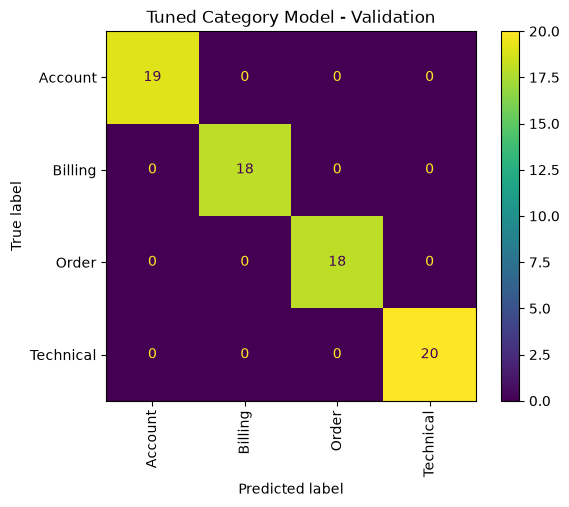

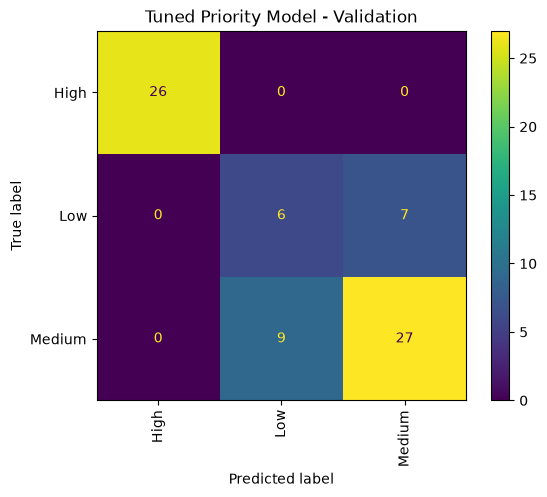

In [61]:
# 45
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Get the best tuned models
best_category_model = category_grid.best_estimator_
best_priority_model = priority_grid.best_estimator_

# Predict validation data
category_val_predictions = best_category_model.predict(X_val)
priority_val_predictions = best_priority_model.predict(X_val)

# Calculate category metrics
category_val_accuracy = accuracy_score(
    y_val_category, category_val_predictions
)
category_val_f1 = f1_score(
    y_val_category, category_val_predictions, average="macro"
)

# Calculate priority metrics
priority_val_accuracy = accuracy_score(
    y_val_priority, priority_val_predictions
)
priority_val_f1 = f1_score(
    y_val_priority, priority_val_predictions, average="macro"
)

# Display results
print("CATEGORY VALIDATION RESULTS")
print("Accuracy:", round(category_val_accuracy, 4))
print("Macro F1:", round(category_val_f1, 4))
print(classification_report(
    y_val_category, category_val_predictions, zero_division=0
))

print("\nPRIORITY VALIDATION RESULTS")
print("Accuracy:", round(priority_val_accuracy, 4))
print("Macro F1:", round(priority_val_f1, 4))
print(classification_report(
    y_val_priority, priority_val_predictions, zero_division=0
))

# Category confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val_category,
    category_val_predictions,
    xticks_rotation="vertical"
)
plt.title("Tuned Category Model - Validation")
plt.show()

# Priority confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val_priority,
    priority_val_predictions,
    xticks_rotation="vertical"
)
plt.title("Tuned Priority Model - Validation")
plt.show()

In [63]:
#46
# Create a table of priority prediction results
error_analysis = pd.DataFrame({
    "Ticket": X_val,
    "Actual Priority": y_val_priority,
    "Predicted Priority": priority_val_predictions
})

# Select incorrectly predicted tickets
confusing_tickets = error_analysis[
    error_analysis["Actual Priority"] !=
    error_analysis["Predicted Priority"]
]

# Display up to 10 confusing examples
print("NUMBER OF MISCLASSIFIED TICKETS:",
      len(confusing_tickets))

print("\n10 CONFUSING TICKET EXAMPLES:")

print(confusing_tickets.head(10).to_string(index=False))

NUMBER OF MISCLASSIFIED TICKETS: 16

10 CONFUSING TICKET EXAMPLES:
                                                                                                                                                                                             Ticket Actual Priority Predicted Priority
        password assistance. i am contacting support because my profile information has changed but will not save. the issue started after i updated my profile. please help me resolve this issue.          Medium                Low
                   account locked. i am contacting support because i cannot reset my password using the recovery page. i have tried again using another browser. please help me resolve this issue.          Medium                Low
          login problem. i am contacting support because the search results do not appear after i submit a query. i am using the latest version available to me. please help me resolve this issue.             Low             Medium
         

In [64]:
#47
# Display 10 misclassified tickets clearly
print("ERROR ANALYSIS - 10 CONFUSING TICKETS")
print("=" * 60)

for number, (index, row) in enumerate(
    confusing_tickets.head(10).iterrows(), start=1
):
    print(f"\nTicket {number}")
    print("Ticket Text:", row["Ticket"])
    print("Actual Priority:", row["Actual Priority"])
    print("Predicted Priority:", row["Predicted Priority"])
    print("-" * 60)

ERROR ANALYSIS - 10 CONFUSING TICKETS

Ticket 1
Ticket Text: password assistance. i am contacting support because my profile information has changed but will not save. the issue started after i updated my profile. please help me resolve this issue.
Actual Priority: Medium
Predicted Priority: Low
------------------------------------------------------------

Ticket 2
Ticket Text: account locked. i am contacting support because i cannot reset my password using the recovery page. i have tried again using another browser. please help me resolve this issue.
Actual Priority: Medium
Predicted Priority: Low
------------------------------------------------------------

Ticket 3
Ticket Text: login problem. i am contacting support because the search results do not appear after i submit a query. i am using the latest version available to me. please help me resolve this issue.
Actual Priority: Low
Predicted Priority: Medium
------------------------------------------------------------

Ticket 4
Ticke

In [65]:
#48
# Count the different types of priority prediction errors
error_patterns = (
    confusing_tickets.groupby(
        ["Actual Priority", "Predicted Priority"]
    )
    .size()
    .reset_index(name="Number of Tickets")
)

print("PRIORITY ERROR PATTERN ANALYSIS")
print("=" * 50)
print(error_patterns.to_string(index=False))

print("\nOBSERVATIONS:")
print("1. The model confuses Low and Medium priorities.")
print("2. Some Medium tickets are predicted as Low.")
print("3. Some Low tickets are predicted as Medium.")
print("4. High priority was classified correctly in validation.")
print("5. More varied and independent training examples may help.")

# Save error analysis
confusing_tickets.to_csv(
    "priority_error_analysis.csv",
    index=False
)

print("\nError analysis saved successfully!")

PRIORITY ERROR PATTERN ANALYSIS
Actual Priority Predicted Priority  Number of Tickets
            Low             Medium                  7
         Medium                Low                  9

OBSERVATIONS:
1. The model confuses Low and Medium priorities.
2. Some Medium tickets are predicted as Low.
3. Some Low tickets are predicted as Medium.
4. High priority was classified correctly in validation.
5. More varied and independent training examples may help.

Error analysis saved successfully!


In [66]:
# 49
# Predict category and priority on test data
category_test_predictions = best_category_model.predict(X_test)
priority_test_predictions = best_priority_model.predict(X_test)

# Calculate test accuracy
category_test_accuracy = accuracy_score(
    y_test_category, category_test_predictions
)

priority_test_accuracy = accuracy_score(
    y_test_priority, priority_test_predictions
)

# Calculate macro F1
category_test_f1 = f1_score(
    y_test_category, category_test_predictions, average="macro"
)

priority_test_f1 = f1_score(
    y_test_priority, priority_test_predictions, average="macro"
)

# Display final test results
print("TUNED BASELINE MODEL - TEST RESULTS")
print("=" * 45)

print("\nCATEGORY MODEL")
print("Accuracy:", round(category_test_accuracy, 4))
print("Macro F1:", round(category_test_f1, 4))

print("\nPRIORITY MODEL")
print("Accuracy:", round(priority_test_accuracy, 4))
print("Macro F1:", round(priority_test_f1, 4))

print("\nCategory Classification Report:")
print(classification_report(
    y_test_category,
    category_test_predictions,
    zero_division=0
))

print("\nPriority Classification Report:")
print(classification_report(
    y_test_priority,
    priority_test_predictions,
    zero_division=0
))

TUNED BASELINE MODEL - TEST RESULTS

CATEGORY MODEL
Accuracy: 1.0
Macro F1: 1.0

PRIORITY MODEL
Accuracy: 0.76
Macro F1: 0.6859

Category Classification Report:
              precision    recall  f1-score   support

     Account       1.00      1.00      1.00        18
     Billing       1.00      1.00      1.00        19
       Order       1.00      1.00      1.00        19
   Technical       1.00      1.00      1.00        19

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75


Priority Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        26
         Low       0.33      0.29      0.31        14
      Medium       0.73      0.77      0.75        35

    accuracy                           0.76        75
   macro avg       0.69      0.69      0.69        75
weighted avg       0.75      0.76      0.75  

In [67]:
#50
import joblib

# Save tuned category model
joblib.dump(
    best_category_model,
    "tuned_category_model.pkl"
)

# Save tuned priority model
joblib.dump(
    best_priority_model,
    "tuned_priority_model.pkl"
)

# Save test evaluation results
baseline_results = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression"
    ],
    "Category Test Accuracy": [
        category_test_accuracy * 100
    ],
    "Category Macro F1": [
        category_test_f1
    ],
    "Priority Test Accuracy": [
        priority_test_accuracy * 100
    ],
    "Priority Macro F1": [
        priority_test_f1
    ]
})

baseline_results.to_csv(
    "tuned_baseline_results.csv",
    index=False
)

print("Tuned baseline models saved successfully!")
print("\nFinal baseline results:")
print(baseline_results.to_string(index=False))

Tuned baseline models saved successfully!

Final baseline results:
                       Model  Category Test Accuracy  Category Macro F1  Priority Test Accuracy  Priority Macro F1
TF-IDF + Logistic Regression                   100.0                1.0                    76.0           0.685897


In [68]:
# 51
import transformers
import torch
from transformers import Trainer, TrainingArguments

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)

print("\nTrainer imported successfully!")
print("TrainingArguments imported successfully!")

Transformers version: 5.22.2
PyTorch version: 2.15.0+cpu

Trainer imported successfully!
TrainingArguments imported successfully!


In [69]:
# 52
from torch.utils.data import Dataset
from sklearn.preprocessing import LabelEncoder

# Create category label encoder
category_encoder_clean = LabelEncoder()

y_train_cat_encoded = category_encoder_clean.fit_transform(
    y_train_category
)

y_val_cat_encoded = category_encoder_clean.transform(
    y_val_category
)

y_test_cat_encoded = category_encoder_clean.transform(
    y_test_category
)

# Tokenize training, validation and testing tickets
train_tokens = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

val_tokens = tokenizer(
    X_val.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_tokens = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

# Create PyTorch dataset class
class TicketDataset(Dataset):

    def __init__(self, tokens, labels):
        self.tokens = tokens
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            key: torch.tensor(value[index])
            for key, value in self.tokens.items()
        }

        item["labels"] = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return item


# Prepare category datasets
category_train_dataset = TicketDataset(
    train_tokens, y_train_cat_encoded
)

category_val_dataset = TicketDataset(
    val_tokens, y_val_cat_encoded
)

category_test_dataset = TicketDataset(
    test_tokens, y_test_cat_encoded
)

print("Category training records:", len(category_train_dataset))
print("Category validation records:", len(category_val_dataset))
print("Category testing records:", len(category_test_dataset))

print("\nCategory Trainer datasets prepared successfully!")

Category training records: 350
Category validation records: 75
Category testing records: 75

Category Trainer datasets prepared successfully!


In [70]:
# 53
# Create priority label encoder
priority_encoder_clean = LabelEncoder()

y_train_pri_encoded = priority_encoder_clean.fit_transform(
    y_train_priority
)

y_val_pri_encoded = priority_encoder_clean.transform(
    y_val_priority
)

y_test_pri_encoded = priority_encoder_clean.transform(
    y_test_priority
)

# Prepare priority datasets
priority_train_dataset = TicketDataset(
    train_tokens, y_train_pri_encoded
)

priority_val_dataset = TicketDataset(
    val_tokens, y_val_pri_encoded
)

priority_test_dataset = TicketDataset(
    test_tokens, y_test_pri_encoded
)

print("Priority training records:", len(priority_train_dataset))
print("Priority validation records:", len(priority_val_dataset))
print("Priority testing records:", len(priority_test_dataset))

print("\nPriority Trainer datasets prepared successfully!")

Priority training records: 350
Priority validation records: 75
Priority testing records: 75

Priority Trainer datasets prepared successfully!


In [71]:
# 54
import inspect
import numpy as np
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

# Load a fresh DistilBERT category model
category_trainer_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(category_encoder_clean.classes_)
)

# Calculate evaluation metrics
def calculate_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro")
    }

# Configure training arguments
training_parameters = {
    "output_dir": "./category_trainer_results",
    "per_device_train_batch_size": 8,
    "per_device_eval_batch_size": 8,
    "num_train_epochs": 1,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "save_strategy": "no",
    "logging_steps": 20,
    "report_to": "none"
}

# Support the installed Transformers version
argument_names = inspect.signature(TrainingArguments.__init__).parameters

if "eval_strategy" in argument_names:
    training_parameters["eval_strategy"] = "epoch"
else:
    training_parameters["evaluation_strategy"] = "epoch"

category_training_args = TrainingArguments(**training_parameters)

# Configure Hugging Face Trainer
trainer_parameters = {
    "model": category_trainer_model,
    "args": category_training_args,
    "train_dataset": category_train_dataset,
    "eval_dataset": category_val_dataset,
    "compute_metrics": calculate_metrics
}

trainer_names = inspect.signature(Trainer.__init__).parameters

if "processing_class" in trainer_names:
    trainer_parameters["processing_class"] = tokenizer
else:
    trainer_parameters["tokenizer"] = tokenizer

category_trainer = Trainer(**trainer_parameters)

print("Category DistilBERT Trainer configured successfully!")
print("Training epochs:", 1)
print("Batch size:", 8)
print("Evaluation metrics: Accuracy and Macro F1")

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 223.63it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Category DistilBERT Trainer configured successfully!
Training epochs: 1
Batch size: 8
Evaluation metrics: Accuracy and Macro F1


In [72]:
# 55
import time

# Record training start time
category_start_time = time.time()

# Train the category model using Hugging Face Trainer
category_train_output = category_trainer.train()

# Calculate training time
category_training_time = time.time() - category_start_time

print("\nCategory DistilBERT Trainer training completed!")

print(
    "Training time:",
    round(category_training_time, 2),
    "seconds"
)

print(
    "Final training loss:",
    round(category_train_output.training_loss, 4)
)

d:\ai-training-week3\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.022635,0.874829,0.973333,0.974206



Category DistilBERT Trainer training completed!
Training time: 166.52 seconds
Final training loss: 1.1444


In [73]:
#56 Evaluate category model on unseen test tickets
category_test_output = category_trainer.predict(
    category_test_dataset
)

# Get predicted labels
category_bert_predictions = np.argmax(
    category_test_output.predictions,
    axis=1
)

# Calculate test metrics
category_bert_test_accuracy = accuracy_score(
    y_test_cat_encoded,
    category_bert_predictions
)

category_bert_test_f1 = f1_score(
    y_test_cat_encoded,
    category_bert_predictions,
    average="macro"
)

print("DISTILBERT CATEGORY TEST RESULTS")
print("Accuracy:", round(category_bert_test_accuracy, 4))
print("Macro F1:", round(category_bert_test_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test_cat_encoded,
    category_bert_predictions,
    target_names=category_encoder_clean.classes_,
    zero_division=0
))

d:\ai-training-week3\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DISTILBERT CATEGORY TEST RESULTS
Accuracy: 1.0
Macro F1: 1.0

Classification Report:
              precision    recall  f1-score   support

     Account       1.00      1.00      1.00        18
     Billing       1.00      1.00      1.00        19
       Order       1.00      1.00      1.00        19
   Technical       1.00      1.00      1.00        19

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75



In [74]:
# 57
# Load a fresh DistilBERT priority model
priority_trainer_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(priority_encoder_clean.classes_)
)

# Configure priority training arguments
priority_training_args = TrainingArguments(
    output_dir="./priority_trainer_results",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=1,
    learning_rate=2e-5,
    weight_decay=0.01,
    save_strategy="no",
    logging_steps=20,
    report_to="none",
    eval_strategy="epoch"
)

# Configure Hugging Face Trainer
priority_trainer_parameters = {
    "model": priority_trainer_model,
    "args": priority_training_args,
    "train_dataset": priority_train_dataset,
    "eval_dataset": priority_val_dataset,
    "compute_metrics": calculate_metrics
}

if "processing_class" in inspect.signature(Trainer.__init__).parameters:
    priority_trainer_parameters["processing_class"] = tokenizer
else:
    priority_trainer_parameters["tokenizer"] = tokenizer

priority_trainer = Trainer(**priority_trainer_parameters)

print("Priority DistilBERT Trainer configured successfully!")
print("Training epochs: 1")
print("Batch size: 8")

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 358.31it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Priority DistilBERT Trainer configured successfully!
Training epochs: 1
Batch size: 8


In [75]:
# 58
import time

# Record training start time
priority_start_time = time.time()

# Train priority model using Hugging Face Trainer
priority_train_output = priority_trainer.train()

# Calculate training time
priority_training_time = time.time() - priority_start_time

print("\nPriority DistilBERT Trainer training completed!")

print(
    "Training time:",
    round(priority_training_time, 2),
    "seconds"
)

print(
    "Final training loss:",
    round(priority_train_output.training_loss, 4)
)

d:\ai-training-week3\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.005119,0.999530,0.480000,0.216216



Priority DistilBERT Trainer training completed!
Training time: 160.29 seconds
Final training loss: 1.0406


In [76]:
#59
# Evaluate priority model on test dataset
priority_test_output = priority_trainer.predict(
    priority_test_dataset
)

# Get predicted labels
priority_bert_predictions = np.argmax(
    priority_test_output.predictions,
    axis=1
)

# Calculate test metrics
priority_bert_test_accuracy = accuracy_score(
    y_test_pri_encoded,
    priority_bert_predictions
)

priority_bert_test_f1 = f1_score(
    y_test_pri_encoded,
    priority_bert_predictions,
    average="macro"
)

print("DISTILBERT PRIORITY TEST RESULTS")
print("Accuracy:", round(priority_bert_test_accuracy, 4))
print("Macro F1:", round(priority_bert_test_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test_pri_encoded,
    priority_bert_predictions,
    target_names=priority_encoder_clean.classes_,
    zero_division=0
))

d:\ai-training-week3\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DISTILBERT PRIORITY TEST RESULTS
Accuracy: 0.4667
Macro F1: 0.2121

Classification Report:
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        26
         Low       0.00      0.00      0.00        14
      Medium       0.47      1.00      0.64        35

    accuracy                           0.47        75
   macro avg       0.16      0.33      0.21        75
weighted avg       0.22      0.47      0.30        75



In [84]:
# 60
# Final comparison: Tuned baseline vs DistilBERT

final_comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "DistilBERT Trainer"
    ],
    "Category Test Accuracy (%)": [
        category_test_accuracy * 100,
        category_bert_test_accuracy * 100
    ],
    "Category Macro F1": [
        category_test_f1,
        category_bert_test_f1
    ],
    "Priority Test Accuracy (%)": [
        priority_test_accuracy * 100,
        priority_bert_test_accuracy * 100
    ],
    "Priority Macro F1": [
        priority_test_f1,
        priority_bert_test_f1
    ],
    "Training Time": [
        "Not recorded",
        "326.81 seconds"
    ],
    "Inference Time per Ticket (ms)": [
        baseline_ms,
        distilbert_ms
    ]
})

print("FINAL MODEL COMPARISON")
print("=" * 90)
print(final_comparison.to_string(index=False))

# Save updated comparison
final_comparison.to_csv("final_model_comparison.csv", index=False)
print("\nComparison saved successfully!")

FINAL MODEL COMPARISON
                       Model  Category Test Accuracy (%)  Category Macro F1  Priority Test Accuracy (%)  Priority Macro F1  Training Time  Inference Time per Ticket (ms)
TF-IDF + Logistic Regression                       100.0                1.0                   76.000000           0.685897   Not recorded                       12.949680
          DistilBERT Trainer                       100.0                1.0                   46.666667           0.212121 326.81 seconds                      381.967168

Comparison saved successfully!


In [85]:
# 61
import os
import joblib

# Create final model folders
os.makedirs("final_category_model", exist_ok=True)
os.makedirs("final_priority_model", exist_ok=True)

# Save final DistilBERT models
category_trainer_model.save_pretrained("final_category_model")
priority_trainer_model.save_pretrained("final_priority_model")

# Save tokenizer
tokenizer.save_pretrained("final_category_model")
tokenizer.save_pretrained("final_priority_model")

# Save label encoders
joblib.dump(
    category_encoder_clean,
    "final_category_model/category_encoder.pkl"
)

joblib.dump(
    priority_encoder_clean,
    "final_priority_model/priority_encoder.pkl"
)

# Save final model comparison
final_comparison.to_csv(
    "final_model_comparison.csv",
    index=False
)

# Save evaluation metrics
joblib.dump(
    {
        "category_test_accuracy": category_bert_test_accuracy,
        "category_test_macro_f1": category_bert_test_f1,
        "priority_test_accuracy": priority_bert_test_accuracy,
        "priority_test_macro_f1": priority_bert_test_f1
    },
    "distilbert_test_metrics.pkl"
)

print("FINAL MODELS SAVED SUCCESSFULLY!")
print("Category DistilBERT model saved.")
print("Priority DistilBERT model saved.")
print("Label encoders saved.")
print("Final comparison CSV saved.")
print("DistilBERT test metrics saved.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.25s/it]

FINAL MODELS SAVED SUCCESSFULLY!
Category DistilBERT model saved.
Priority DistilBERT model saved.
Label encoders saved.
Final comparison CSV saved.
DistilBERT test metrics saved.


In [86]:
# 62
import time

# Prepare one test ticket
sample_ticket = X_test.iloc[0]

# Measure TF-IDF + Logistic Regression inference time
start_time = time.perf_counter()

for _ in range(100):
    best_category_model.predict([sample_ticket])
    best_priority_model.predict([sample_ticket])

baseline_time = (time.perf_counter() - start_time) / 100

# Measure DistilBERT inference time
category_inputs = tokenizer(
    [sample_ticket],
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=128
)

priority_inputs = category_inputs.copy()

category_trainer_model.eval()
priority_trainer_model.eval()

start_time = time.perf_counter()

for _ in range(100):
    with torch.no_grad():
        category_trainer_model(**category_inputs)
        priority_trainer_model(**priority_inputs)

distilbert_time = (time.perf_counter() - start_time) / 100

# Convert seconds to milliseconds per ticket
baseline_ms = baseline_time * 1000
distilbert_ms = distilbert_time * 1000

print("INFERENCE TIME PER TICKET")
print("TF-IDF + Logistic Regression:", round(baseline_ms, 2), "ms")
print("DistilBERT:", round(distilbert_ms, 2), "ms")

INFERENCE TIME PER TICKET
TF-IDF + Logistic Regression: 10.48 ms
DistilBERT: 361.59 ms
